# Clase 5 — Ingeniería de Embeddings y Chunking

En esta clase transformás documentos en unidades recuperables y trazables. El foco no es “guardar vectores”, sino diseñar una representación que después permita recuperar evidencia útil.

> **Vector store canónico del curso:** Qdrant.  
> La notebook puede usar Qdrant Local Mode cuando la dependencia está instalada y, si no, ejecuta un backend en memoria con el mismo contrato. El fallback se muestra de forma explícita.

## Resultado de la clase

Al finalizar vas a tener:

- un contrato reusable de embeddings;
- una implementación real opcional con `sentence-transformers`;
- un embedding determinístico para pruebas sin descargas;
- estrategias fixed-size, recursive y semantic;
- chunks con IDs estables y metadata trazable;
- un `Retriever` compatible con Qdrant e in-memory;
- búsquedas semánticas y filtros;
- un manifiesto de indexación para la Clase 6.

---

### Contrato de continuidad

- Las notebooks de las clases 1 y 2 son la **base publicada e inmutable**.
- Esta clase continúa sobre `ai_agent_project/`; no crea un proyecto paralelo.
- Incremento: **embeddings, chunking e interfaz Retriever**.
- El modo predeterminado es local/simulado y no consume APIs por accidente.
- Los modos reales requieren variables de entorno explícitas.

La notebook separa experimentos visibles de módulos reutilizables y deja un checkpoint para la clase siguiente.


## Mapa del laboratorio

1. Comprender qué representa un embedding.
2. Medir similitud y distinguir consultas de documentos.
3. Diseñar la unidad recuperable mediante chunking.
4. Comparar estrategias con evidencia visible.
5. Construir IDs y metadata estables.
6. Indexar detrás de un contrato.
7. Buscar, filtrar y diagnosticar resultados.
8. Guardar el checkpoint.

La calidad semántica real debe medirse con un modelo real. El modo determinístico sirve para aprender el pipeline y ejecutar tests reproducibles.

### Patrón de trabajo de esta notebook

En cada incremento vamos a seguir la misma secuencia que quedó validada en la Clase 3:

1. **comprender el problema y el contrato**;
2. **construir una versión visible y mínima**;
3. **probar un caso exitoso y un borde relevante**;
4. **persistir la implementación en `src/`**;
5. **importar el módulo generado y volver a verificarlo**.

Los servicios externos permanecen desactivados por defecto. Las celdas que usan APIs, Ollama, Qdrant Server u otros servicios requieren una habilitación explícita.

In [1]:
from pathlib import Path
import hashlib
import importlib.util
import json
import math
import os
import re
import shutil
import subprocess
import sys
import textwrap
import time
from collections import Counter
from dataclasses import asdict, dataclass
from typing import Any


PROJECT_DIR = Path("ai_agent_project")
SRC_DIR = PROJECT_DIR / "src" / "ai_agent_course"
DATA_DIR = PROJECT_DIR / "data"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
TESTS_DIR = PROJECT_DIR / "tests"

for directory in (SRC_DIR, DATA_DIR, ARTIFACTS_DIR, TESTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
(SRC_DIR / "__init__.py").touch()

if str(PROJECT_DIR / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR / "src"))

def write_file(path: Path, content: str) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(textwrap.dedent(content).strip() + "\n", encoding="utf-8")
    print("✓", path.relative_to(PROJECT_DIR))

def show_table(rows, columns=None):
    try:
        import pandas as pd
        frame = pd.DataFrame(rows)
        if columns:
            frame = frame[columns]
        display(frame)
    except Exception:
        for row in rows:
            print(row)

print(f"Proyecto incremental: {PROJECT_DIR}")

Proyecto incremental: ai_agent_project


### Checkpoint de continuidad

Se verifican los componentes previos antes de sumar el incremento. Un faltante se informa; no se oculta recreando silenciosamente todo el proyecto.

In [2]:
_continuity_root = PROJECT_DIR
_continuity = ['src/ai_agent_course/providers.py']
continuity_status = [{"path": p, "available": (_continuity_root / p).exists()} for p in _continuity]
for item in continuity_status:
    print(("✓" if item["available"] else "·"), item["path"])
missing_prerequisites = [item["path"] for item in continuity_status if not item["available"]]
if missing_prerequisites:
    print("Aviso: faltan componentes previos:", missing_prerequisites)
else:
    print("Continuidad verificada.")

✓ src/ai_agent_course/providers.py
Continuidad verificada.


## 1. Dependencias y modos

- `sentence-transformers`: embeddings semánticos reales.
- `qdrant-client`: Qdrant Local Mode o conexión a un servidor.
- backend en memoria: fallback didáctico y tests.

La notebook no confunde el fallback con Qdrant: el backend activo aparece en las salidas y en el reporte final.

In [5]:
RUN_INSTALLS = os.getenv("RUN_INSTALLS", "0") == "1"
PACKAGES = [
    "numpy>=1.26",
    "sentence-transformers>=3.0",
    "qdrant-client==1.18.0",
    "pytest>=8.0",
    "matplotlib>=3.8",
    "pandas>=2.0",
]

if RUN_INSTALLS:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *PACKAGES])
else:
    print("Para habilitar el laboratorio real:")
    print("python -m pip install " + " ".join(PACKAGES))

REQUEST_REAL_EMBEDDINGS = True
REQUEST_QDRANT = True

HAS_SENTENCE_TRANSFORMERS = importlib.util.find_spec("sentence_transformers") is not None
HAS_QDRANT = importlib.util.find_spec("qdrant_client") is not None

USE_REAL_EMBEDDINGS = REQUEST_REAL_EMBEDDINGS and HAS_SENTENCE_TRANSFORMERS
USE_QDRANT = REQUEST_QDRANT and HAS_QDRANT

execution_mode = {
    "embeddings": "sentence-transformers" if USE_REAL_EMBEDDINGS else "deterministic-semantic-smoke",
    "vector_store": "qdrant-local" if USE_QDRANT else "in-memory-compatible",
    "requested_real_embeddings": REQUEST_REAL_EMBEDDINGS,
    "requested_qdrant": REQUEST_QDRANT,
}
execution_mode



Para habilitar el laboratorio real:
python -m pip install numpy>=1.26 sentence-transformers>=3.0 qdrant-client==1.18.0 pytest>=8.0 matplotlib>=3.8 pandas>=2.0


{'embeddings': 'sentence-transformers',
 'vector_store': 'qdrant-local',
 'requested_real_embeddings': True,
 'requested_qdrant': True}

## 2. Embeddings: representar significado

Un embedding convierte texto en un vector. La similitud coseno compara la dirección de dos vectores normalizados:

- cerca de `1`: alta similitud;
- cerca de `0`: poca relación;
- valores negativos: direcciones opuestas en algunos espacios.

La similitud por sí sola no garantiza relevancia: depende del modelo, del dominio, del chunking y de la consulta.

In [6]:
import numpy as np  # Importamos NumPy para trabajar con vectores y operaciones matemáticas.


# Recibe dos vectores y devuelve su similitud coseno como un número decimal.
def cosine_similarity(a, b) -> float:
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    # La norma de cada vector arma el denominador de la fórmula de similitud coseno.
    denominator = float(np.linalg.norm(a) * np.linalg.norm(b))

    # Si algún vector tiene longitud cero, devolvemos 0.0 para evitar una división por cero.
    return 0.0 if denominator == 0 else float(np.dot(a, b) / denominator)


print("coseno(v, v):", cosine_similarity([1, 2], [1, 2]))
# Compara un vector consigo mismo.
# Resultado esperado: 1.0, porque ambos apuntan exactamente en la misma dirección.

print("coseno(ortogonales):", cosine_similarity([1, 0], [0, 1]))
# Compara dos vectores perpendiculares, que forman un ángulo de 90 grados.
# Resultado esperado: 0.0, porque no apuntan en la misma dirección.


coseno(v, v): 0.9999999999999998
coseno(ortogonales): 0.0


Matplotlib is building the font cache; this may take a moment.


Mismo vector:


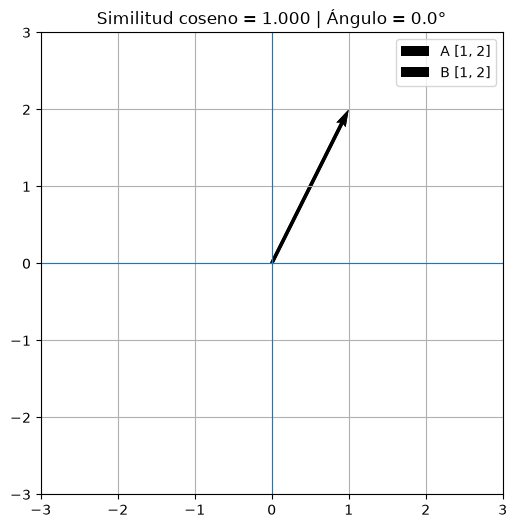

Perpendiculares:


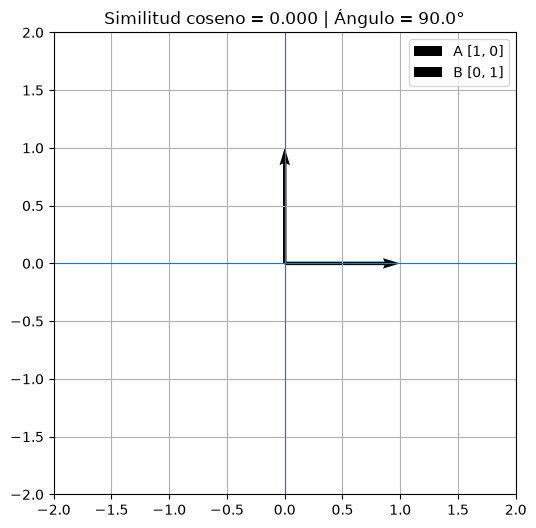

Misma dirección:


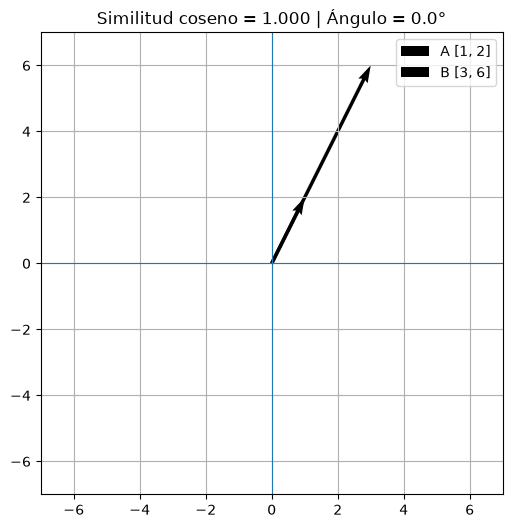

In [7]:
import matplotlib.pyplot as plt


def plot_vectors(a, b):
    # Calculamos la similitud y el ángulo entre los vectores.
    similarity = cosine_similarity(a, b)
    angle = np.degrees(np.arccos(np.clip(similarity, -1, 1)))

    # Dibujamos ambos vectores desde el origen.
    plt.figure(figsize=(6, 6))
    plt.quiver(0, 0, a[0], a[1],
               angles="xy", scale_units="xy", scale=1,
               label=f"A {a}")

    plt.quiver(0, 0, b[0], b[1],
               angles="xy", scale_units="xy", scale=1,
               label=f"B {b}")

    # Ajustamos los límites del gráfico.
    max_value = max(abs(x) for x in a + b) + 1
    plt.xlim(-max_value, max_value)
    plt.ylim(-max_value, max_value)

    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.grid()
    plt.legend()
    plt.gca().set_aspect("equal")

    plt.title(
        f"Similitud coseno = {similarity:.3f} | "
        f"Ángulo = {angle:.1f}°"
    )

    plt.show()


# ---------------------------------------------------------
# Caso 1: mismo vector
# Misma dirección → similitud = 1
# ---------------------------------------------------------

a = [1, 2]
b = [1, 2]

print("Mismo vector:")
plot_vectors(a, b)


# ---------------------------------------------------------
# Caso 2: vectores perpendiculares
# Ángulo de 90° → similitud = 0
# ---------------------------------------------------------

a = [1, 0]
b = [0, 1]

print("Perpendiculares:")
plot_vectors(a, b)


# ---------------------------------------------------------
# Caso 3: distinta magnitud, misma dirección
# Aunque B es mucho más largo, la dirección es la misma.
# Por eso la similitud sigue siendo 1.
# ---------------------------------------------------------

a = [1, 2]
b = [3, 6]

print("Misma dirección:")
plot_vectors(a, b)

### Contrato de embeddings

Separamos `embed_documents()` de `embed_query()` aunque algunas implementaciones usen el mismo cálculo. Hay modelos que distinguen explícitamente consultas y documentos mediante prefijos o cabezales diferentes.

> **Alcance del laboratorio offline:** el provider determinístico permite recorrer el pipeline sin credenciales, pero no reproduce el espacio vectorial de Gemini. Los índices generados con providers diferentes son incompatibles y no deben mezclarse.


### 2.1 Construir una representación mínima antes del módulo

Un embedding provider debe garantizar tres propiedades observables: dimensión estable, determinismo para la misma entrada y una interfaz diferente para documentos y consultas. El experimento usa una representación hash liviana; no pretende sustituir un modelo semántico real.

In [8]:
import hashlib
import re
import numpy as np

np.set_printoptions(
    linewidth=200,   # ancho máximo antes de cortar la línea
    precision=3,     # cantidad de decimales
    suppress=True    # evita notación científica innecesaria
)
class HashEmbeddingPreview:
    # Embedder didáctico basado en hashing.
    # No representa significado semántico real.
    model_name = "hash-preview"

    def __init__(self, dimension: int = 16):
        # Define cuántas dimensiones tendrá cada vector.
        if dimension < 4:
            raise ValueError("dimension debe ser al menos 4")

        self.dimension = dimension

    def _embed(self, text: str) -> list[float]:
        # Crea un vector inicial de ceros.
        vector = np.zeros(self.dimension, dtype=float)

        # Separa el texto en palabras.
        tokens = re.findall(r"\w+", text.lower())
        print("Tokens:", tokens)

        for token in tokens:
            # Genera un hash determinístico para cada palabra.
            digest = hashlib.sha256(token.encode("utf-8")).digest()

            # Usa el hash para elegir una posición del vector.
            index = int.from_bytes(digest[:4], "big") % self.dimension

            # Incrementa esa dimensión.
            vector[index] += 1.0

        print("Vector antes de normalizar:", vector)

        # Calcula la longitud del vector.
        norm = np.linalg.norm(vector)

        # Normaliza el vector para que tenga longitud 1.
        normalized = vector / norm if norm else vector

        print("Vector normalizado:", normalized)

        return normalized.tolist()

    def embed_documents(self, texts):
        # Genera un vector por cada documento.
        return [self._embed(text) for text in texts]

    def embed_query(self, text):
        # Genera el vector de una consulta.
        return self._embed(text)


# Creamos un embedder de 16 dimensiones.
preview_embedder = HashEmbeddingPreview(dimension=16)

# El mismo texto debe generar el mismo vector.
first = preview_embedder.embed_query("política de vacaciones")
second = preview_embedder.embed_query("política de vacaciones")

# Un texto distinto genera otro vector.
different = preview_embedder.embed_query("reintegro de gastos")

# Verificaciones simples.
assert len(first) == 16
assert first == second
assert first != different

# Resumen del resultado.
{
    "model": preview_embedder.model_name,
    "dimension": len(first),
    "deterministic": first == second,
    "sample": first[:5],
}

Tokens: ['política', 'de', 'vacaciones']
Vector antes de normalizar: [0. 1. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Vector normalizado: [0.    0.577 0.    0.577 0.577 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.   ]
Tokens: ['política', 'de', 'vacaciones']
Vector antes de normalizar: [0. 1. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Vector normalizado: [0.    0.577 0.    0.577 0.577 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.   ]
Tokens: ['reintegro', 'de', 'gastos']
Vector antes de normalizar: [0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Vector normalizado: [0.    0.    0.577 0.    0.577 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.577]


{'model': 'hash-preview',
 'dimension': 16,
 'deterministic': True,
 'sample': [0.0,
  0.5773502691896258,
  0.0,
  0.5773502691896258,
  0.5773502691896258]}

### 2.2 Persistir el provider de embeddings

El módulo completo agrega normalización, sinónimos de dominio, provider local determinístico y la integración opcional con SentenceTransformers.

In [9]:
%%writefile ai_agent_project/src/ai_agent_course/embeddings.py

from __future__ import annotations

import hashlib
import os
import re
import unicodedata
from typing import Protocol, Sequence

import numpy as np


class EmbeddingProvider(Protocol):
    # Contrato común para cualquier proveedor de embeddings.
    model_name: str
    dimension: int

    def embed_documents(self, texts: Sequence[str]) -> list[list[float]]: ...
    def embed_query(self, text: str) -> list[float]: ...


def _normalize(text: str) -> list[str]:
    # Pasa a minúsculas y separa letras de sus acentos.
    text = unicodedata.normalize("NFKD", text.lower())

    # Elimina los acentos para normalizar palabras equivalentes.
    text = "".join(
        char for char in text
        if not unicodedata.combining(char)
    )

    # Extrae las palabras del texto.
    tokens = re.findall(r"[a-z0-9]+", text)

    # Agrupa palabras relacionadas bajo un mismo término.
    synonyms = {
        "licencia": "vacaciones",
        "descanso": "vacaciones",
        "anual": "vacaciones",
        "reintegro": "gastos",
        "reembolsos": "gastos",
        "comprobante": "gastos",
        "credencial": "seguridad",
        "credenciales": "seguridad",
        "contrasena": "seguridad",
        "clave": "seguridad",
        "password": "seguridad",
        "home": "remoto",
        "office": "remoto",
        "teletrabajo": "remoto",
        "distancia": "remoto",
    }

    # Reemplaza sinónimos y devuelve los tokens normalizados.
    return [synonyms.get(token, token) for token in tokens]


class DeterministicSemanticEmbeddings:
    # Fallback didáctico: simula cierta similitud semántica
    # sin utilizar un modelo real de embeddings.
    model_name = "deterministic-semantic-smoke-v3"

    # Todos los vectores tendrán 192 dimensiones.
    dimension = 192

    # Los vectores se normalizan con norma L2.
    normalization = "l2"

    # Las primeras dimensiones representan tópicos conocidos.
    # Tópicos manuales para simular similitud semántica en el fallback didáctico.
    TOPICS = {
        0: {"vacaciones", "anticipacion"},
        1: {"gastos", "fiscal", "finanzas", "reembolso"},
        2: {"seguridad", "incidente", "sesiones", "exposicion"},
        3: {"remoto", "presencialidad", "disponibilidad"},
        4: {"capacitacion", "curso", "programa", "formacion"},
        5: {"reunion", "reuniones", "agenda", "decisiones"},
    }

    def _embed(self, text: str) -> list[float]:
        # Crea inicialmente un vector de 192 ceros.
        vector = np.zeros(self.dimension, dtype=float)

        # Normaliza el texto y obtiene sus tokens.
        tokens = _normalize(text)
        token_set = set(tokens)

        # Asigna más peso a las dimensiones de tópicos detectados.
        for dimension, keywords in self.TOPICS.items():
            matches = len(token_set & keywords)

            if matches:
                vector[dimension] = 4.0 + matches

        # Usa palabras y pares de palabras consecutivas como features
        # para agregar más detalle lexical al vector.
        features = tokens + [
            f"{tokens[index]}_{tokens[index + 1]}"
            for index in range(max(0, len(tokens) - 1))
        ]

        # Reservamos las primeras dimensiones para los tópicos.
        usable_dimensions = self.dimension - 8
        
        for feature in features:
            # Convierte cada feature en una posición reproducible del vector.
            digest = hashlib.sha256(
                feature.encode("utf-8")
            ).digest()

            # Usa solo las dimensiones posteriores a las reservadas para tópicos. (reservamos las primeras 8 dimensiones para los tópicos)
            index = (
                8
                + int.from_bytes(digest[:4], "big")
                % usable_dimensions
            )

            # El hash también determina si suma o resta.
            sign = 1.0 if digest[4] % 2 == 0 else -1.0

            vector[index] += 0.35 * sign

        # Normaliza el vector para que tenga longitud 1.
        norm = float(np.linalg.norm(vector)) or 1.0

        return (vector / norm).tolist()

    # Genera un embedding por cada documento.
    def embed_documents(
        self,
        texts: Sequence[str],
    ) -> list[list[float]]:
        return [self._embed(text) for text in texts]

    # Genera el embedding de una consulta.
    def embed_query(self, text: str) -> list[float]:
        return self._embed(text)


class SentenceTransformerEmbeddings:
    # Implementación que utiliza un modelo real de embeddings.
    def __init__(
        self,
        model_name: str = (
            "sentence-transformers/"
            "paraphrase-multilingual-MiniLM-L12-v2"
        ),
    ):
        try:
            from sentence_transformers import SentenceTransformer

        except ImportError as exc:
            raise RuntimeError(
                "Instalá sentence-transformers "
                "o usá el fallback determinístico."
            ) from exc

        # Carga el modelo seleccionado.
        self.model_name = model_name
        self._model = SentenceTransformer(model_name)

        # Obtiene automáticamente la dimensión del modelo.
        self.dimension = int(
            self._model.get_sentence_embedding_dimension()
        )

        self.normalization = "l2"

    def embed_documents(
        self,
        texts: Sequence[str],
    ) -> list[list[float]]:
        # Genera embeddings reales para todos los textos.
        vectors = self._model.encode(
            list(texts),
            normalize_embeddings=True,
            show_progress_bar=False,
        )

        return vectors.astype(float).tolist()

    def embed_query(self, text: str) -> list[float]:
        # Una query se procesa igual que un documento individual.
        return self.embed_documents([text])[0]


def build_embedding_provider(use_real: bool = False,) -> EmbeddingProvider:

    # Si use_real=True utiliza Sentence Transformers.
    if use_real:
        # Permite cambiar el modelo mediante una variable de entorno.
        model_name = os.getenv(
            "LOCAL_EMBEDDING_MODEL",
            (
                "sentence-transformers/"
                "paraphrase-multilingual-MiniLM-L12-v2"
            ),
        )

        return SentenceTransformerEmbeddings(model_name)

    # Por defecto usa el fallback didáctico y determinístico.
    return DeterministicSemanticEmbeddings()

Writing ai_agent_project/src/ai_agent_course/embeddings.py


In [10]:
import importlib
import ai_agent_course.embeddings as embeddings_module
importlib.reload(embeddings_module)

embedding_provider = embeddings_module.build_embedding_provider(
    use_real=USE_REAL_EMBEDDINGS
)
# Genera un embedding usando el provider activo (real o smoke).
vector = embedding_provider.embed_query("política de vacaciones")
assert len(vector) == embedding_provider.dimension
{"provider": embedding_provider.model_name, "dimension": embedding_provider.dimension}

/Users/gasparcartasso/Desktop/AI Developer/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 20856.76it/s]
/Users/gasparcartasso/Desktop/AI Developer/ai_agent_project/src/ai_agent_course/embeddings.py:164: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self._model.get_sentence_embedding_dimension()


{'provider': 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2',
 'dimension': 384}

### Experimento de similitud

La comparación incluye una paráfrasis y un texto no relacionado. En modo real, la magnitud de la diferencia es evidencia del modelo; en modo smoke, solo valida la mecánica.

In [11]:
# Textos que vamos a comparar semánticamente.
similarity_texts = [
    "La solicitud de vacaciones debe cargarse con anticipación.",
    "El pedido de licencia anual tiene que registrarse antes.",
    "Los comprobantes de gastos vencen a los treinta días.",
]

# Genera un embedding para cada texto.
vectors = embedding_provider.embed_documents(similarity_texts)

# Compara la similitud coseno entre los embeddings.
similarity_rows = [
    {
        # Dos textos relacionados con vacaciones/licencia.
        "par": "vacaciones ↔ licencia",
        "similaridad": round(
            cosine_similarity(vectors[0], vectors[1]), 3
        ),
    },
    {
        # Textos de temas diferentes: vacaciones y gastos.
        "par": "vacaciones ↔ gastos",
        "similaridad": round(
            cosine_similarity(vectors[0], vectors[2]), 3
        ),
    },
]

# Muestra los resultados en formato tabla.
show_table(similarity_rows)

,par,similaridad
0,vacaciones ↔ licencia,0.370
1,vacaciones ↔ gastos,0.248


### Selección del modelo de embeddings

No siempre conviene el modelo más grande. La decisión debe considerar idioma, dominio, dimensión, latencia, licencia y consistencia entre indexación y consulta.

In [12]:
import pandas as pd

model_selection = pd.DataFrame([
    {
        "Criterio": "Idioma",
        "Pregunta": "¿Representa bien español y vocabulario local?",
        "Modelo / recomendación": "paraphrase-multilingual-MiniLM-L12-v2",
        "Riesgo": "baja recuperación por paráfrasis",
    },
    {
        "Criterio": "Dimensión",
        "Pregunta": "¿Cuánto ocupa cada vector?",
        "Modelo / recomendación": "MiniLM (384 dimensiones) si alcanza la calidad",
        "Riesgo": "más memoria y transferencia",
    },
    {
        "Criterio": "Latencia",
        "Pregunta": "¿Cuánto tarda un batch real?",
        "Modelo / recomendación": "MiniLM para priorizar velocidad",
        "Riesgo": "ingesta lenta o búsqueda cara",
    },
    {
        "Criterio": "Versión",
        "Pregunta": "¿Se conserva el mismo modelo al consultar?",
        "Modelo / recomendación": "usar exactamente el mismo modelo",
        "Riesgo": "índice incompatible",
    },
    {
        "Criterio": "Privacidad",
        "Pregunta": "¿El texto sale de la organización?",
        "Modelo / recomendación": "Sentence Transformers local / BGE-M3 local",
        "Riesgo": "incumplimiento de políticas",
    },
])

display(
    model_selection.style
        .hide(axis="index")
        .set_properties(**{
            "text-align": "left",
            "padding": "8px",
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("text-align", "left"),
                    ("font-weight", "bold"),
                    ("padding", "8px"),
                ],
            }
        ])
)

Criterio,Pregunta,Modelo / recomendación,Riesgo
Idioma,¿Representa bien español y vocabulario local?,paraphrase-multilingual-MiniLM-L12-v2,baja recuperación por paráfrasis
Dimensión,¿Cuánto ocupa cada vector?,MiniLM (384 dimensiones) si alcanza la calidad,más memoria y transferencia
Latencia,¿Cuánto tarda un batch real?,MiniLM para priorizar velocidad,ingesta lenta o búsqueda cara
Versión,¿Se conserva el mismo modelo al consultar?,usar exactamente el mismo modelo,índice incompatible
Privacidad,¿El texto sale de la organización?,Sentence Transformers local / BGE-M3 local,incumplimiento de políticas


## 3. Corpus, metadata e identidad

El corpus usa políticas internas ficticias. Cada documento conserva:

- `document_id`: identidad estable;
- `source` y `page`: trazabilidad;
- `topic`, `department` y `active`: metadata filtrable;
- `version`: permite detectar contenido actualizado.

El embedding nunca reemplaza esta información.

In [13]:
POLICIES = [
    {
        "document_id": "POL-VAC-001",
        "source": "politica_vacaciones.md",
        "page": 1,
        "text": (
            "Las solicitudes de vacaciones deben registrarse en la herramienta de RRHH "
            "con al menos 15 días corridos de anticipación. La carga inicia el circuito "
            "de revisión, pero no implica aprobación automática. El líder directo valida "
            "la cobertura operativa y las fechas solicitadas. Si existe una urgencia, la "
            "persona debe documentar la excepción y solicitar aprobación explícita del "
            "líder y de RRHH. Una solicitud ya aprobada puede modificarse únicamente "
            "cancelando las fechas originales y creando una nueva solicitud."
        ),
        "metadata": {
            "topic": "vacaciones",
            "department": "RRHH",
            "active": True,
            "version": "2026.1",
        },
    },
    {
        "document_id": "POL-EXP-002",
        "source": "politica_gastos.md",
        "page": 1,
        "text": (
            "Los reintegros de gastos deben presentarse con comprobante fiscal válido "
            "y una descripción del motivo. El plazo máximo es de 30 días corridos desde "
            "la fecha del gasto. Finanzas puede rechazar comprobantes ilegibles, "
            "duplicados o fuera de plazo. Cuando el gasto se realizó en moneda extranjera, "
            "debe informarse el tipo de cambio aplicado y adjuntarse el resumen correspondiente."
        ),
        "metadata": {
            "topic": "gastos",
            "department": "Finanzas",
            "active": True,
            "version": "2026.2",
        },
    },
    {
        "document_id": "POL-SEC-003",
        "source": "politica_seguridad.md",
        "page": 2,
        "text": (
            "Las credenciales personales no deben compartirse por correo, chat ni "
            "documentos. Ante sospecha de exposición, la persona debe cambiar la clave, "
            "revocar las sesiones activas y abrir inmediatamente un incidente de seguridad. "
            "El incidente debe incluir el sistema afectado, el horario aproximado y el canal "
            "por el que pudo haberse expuesto la credencial. Seguridad puede solicitar "
            "información adicional y debe confirmar el cierre del incidente."
        ),
        "metadata": {
            "topic": "seguridad",
            "department": "Tecnología",
            "active": True,
            "version": "2026.1",
        },
    },
    {
        "document_id": "POL-REM-004",
        "source": "politica_trabajo_remoto.md",
        "page": 1,
        "text": (
            "El trabajo remoto requiere acuerdo previo con el líder y registro en la "
            "herramienta interna. Cada equipo define días de presencialidad según sus "
            "necesidades operativas. Durante la jornada remota la persona debe permanecer "
            "disponible en los canales acordados y cumplir las medidas de seguridad. "
            "El acuerdo puede revisarse cuando cambian las funciones, el equipo o las "
            "condiciones operativas."
        ),
        "metadata": {
            "topic": "trabajo remoto",
            "department": "RRHH",
            "active": True,
            "version": "2026.1",
        },
    },
]
write_file(DATA_DIR / "policies.json", json.dumps(POLICIES, ensure_ascii=False, indent=2))

show_table([
    {
        "document_id": doc["document_id"],
        "source": doc["source"],
        "words": len(doc["text"].split()),
        **doc["metadata"],
    }
    for doc in POLICIES
])

✓ data/policies.json


,document_id,source,words,topic,department,active,version
0,POL-VAC-001,politica_vacaciones.md,77,vacaciones,RRHH,True,2026.1
1,POL-EXP-002,politica_gastos.md,58,gastos,Finanzas,True,2026.2
2,POL-SEC-003,politica_seguridad.md,65,seguridad,Tecnología,True,2026.1
3,POL-REM-004,politica_trabajo_remoto.md,58,trabajo remoto,RRHH,True,2026.1


## 4. Chunking: diseñar la unidad recuperable

Un chunk demasiado grande incorpora ruido y consume contexto. Uno demasiado chico pierde relaciones y puede volverse ambiguo.

Vamos a comparar:

- **fixed-size:** ventana constante con overlap;
- **recursive:** prioriza párrafos y oraciones antes de cortar;
- **semantic:** agrupa oraciones mientras mantengan similitud temática.

### 4.1 Experimentar con tamaño, overlap e identidad

El chunk no es solo texto: necesita una identidad estable y metadata que permitan actualizar, filtrar y citar. Antes de persistir el módulo, observamos el efecto del overlap y validamos configuraciones imposibles.

In [14]:
import hashlib
import re



def normalize_text_preview(text: str) -> str:
    # Elimina espacios repetidos y limpia los extremos.
    return re.sub(r"\s+", " ", text).strip()


def fixed_size_chunks_preview(
    text: str,
    target_words: int = 8,
    overlap_words: int = 2,
) -> list[str]:

    # Valida el tamaño del chunk.
    if target_words <= 0:
        raise ValueError("target_words debe ser positivo")

    # El overlap debe ser menor que el tamaño del chunk.
    if not 0 <= overlap_words < target_words:
        raise ValueError("overlap_words inválido")

    # Normaliza el texto y lo separa en palabras.
    words = normalize_text_preview(text).split()

    # Define cuántas palabras avanzamos entre chunks.
    step = target_words - overlap_words

    # Crea chunks de tamaño fijo con solapamiento.
    return [
        " ".join(words[start:start + target_words])
        for start in range(0, len(words), step)
    ]


def stable_chunk_id_preview(
    document_id: str,
    index: int,
    text: str,
) -> str:

    # Genera un hash corto a partir del contenido del chunk.
    digest = hashlib.sha1(
        normalize_text_preview(text).encode("utf-8")
    ).hexdigest()[:8]

    # Construye un identificador reproducible para el chunk.
    return f"{document_id}:fixed:{index:03d}:{digest}"


# Texto de ejemplo.
sample_text = (
    "uno dos tres cuatro cinco seis siete ocho "
    "nueve diez once doce trece catorce"
)

# Crea chunks de 6 palabras con overlap de 2.
preview_chunks = fixed_size_chunks_preview(
    sample_text,
    target_words=6,
    overlap_words=2,
)

# Genera un ID estable para cada chunk.
preview_ids = [
    stable_chunk_id_preview("doc-demo", i, text)
    for i, text in enumerate(preview_chunks)
]

# Verifica que haya 2 palabras de overlap entre chunks consecutivos.
assert preview_chunks[0].split()[-2:] == preview_chunks[1].split()[:2]

# Verifica que todos los IDs sean únicos.
assert len(preview_ids) == len(set(preview_ids))

# Prueba una configuración inválida de overlap.
try:
    fixed_size_chunks_preview(
        sample_text,
        target_words=5,
        overlap_words=5,
    )

except ValueError as exc:
    invalid_overlap = str(exc)

# Armamos una tabla para visualizar mejor cada chunk y su ID.
chunk_table = pd.DataFrame([
    {
        "Chunk": i,
        "Texto": text,
        "ID": chunk_id,
    }
    for i, (text, chunk_id) in enumerate(
        zip(preview_chunks, preview_ids)
    )
])

display(
    chunk_table.style
        .hide(axis="index")
        .set_properties(**{
            "text-align": "left",
            "padding": "8px",
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("text-align", "left"),
                    ("font-weight", "bold"),
                    ("padding", "8px"),
                ],
            }
        ])
)

print("Caso inválido:", invalid_overlap)

Chunk,Texto,ID
0,uno dos tres cuatro cinco seis,doc-demo:fixed:000:f532e552
1,cinco seis siete ocho nueve diez,doc-demo:fixed:001:3644d856
2,nueve diez once doce trece catorce,doc-demo:fixed:002:a2d24550
3,trece catorce,doc-demo:fixed:003:f18f4819


Caso inválido: overlap_words inválido


### 4.2 Persistir las estrategias de chunking

La implementación completa incorpora fixed-size, párrafos, encabezados, metadata heredada y un contrato uniforme para comparar estrategias.

In [15]:
%%writefile ai_agent_project/src/ai_agent_course/chunking.py

from __future__ import annotations

import hashlib
import re
from typing import Callable


# Normaliza el texto eliminando espacios repetidos.
def normalize_text(text: str) -> str:
    return re.sub(r"\s+", " ", text).strip()


# Genera un ID estable para identificar cada chunk
# de forma reproducible.
def stable_chunk_id(
    document_id: str,
    strategy: str,
    index: int,
    text: str,
) -> str:

    # Genera un hash corto a partir del contenido del chunk.
    digest = hashlib.sha1(
        normalize_text(text).encode("utf-8")
    ).hexdigest()[:8]

    return f"{document_id}:{strategy}:{index:03d}:{digest}"


# Chunking de tamaño fijo:
# corta el texto por cantidad de palabras y mantiene overlap entre chunks.
def fixed_size_chunks(
    text: str,
    *,
    target_words: int = 55,
    overlap_words: int = 10,
) -> list[str]:

    # Valida el tamaño del chunk.
    if target_words <= 0:
        raise ValueError("target_words debe ser positivo")

    # El overlap debe ser menor que el tamaño del chunk.
    if not 0 <= overlap_words < target_words:
        raise ValueError("overlap_words inválido")

    # Normaliza y separa el texto en palabras.
    words = normalize_text(text).split()

    if not words:
        return []

    # Define cuánto avanza cada nuevo chunk.
    step = target_words - overlap_words

    result = []

    for start in range(0, len(words), step):
        piece = words[start:start + target_words]

        # Evita dejar un último chunk demasiado corto.
        if len(piece) < 10 and result:
            result[-1] = normalize_text(
                result[-1] + " " + " ".join(piece)
            )
            break

        result.append(" ".join(piece))

    return result


# Chunking recursivo:
# intenta respetar párrafos y oraciones antes de cortar por tamaño.
def recursive_chunks(
    text: str,
    *,
    target_words: int = 55,
    overlap_words: int = 8,
) -> list[str]:

    # Primero intenta separar el texto por párrafos.
    paragraphs = [
        normalize_text(part)
        for part in re.split(r"\n\s*\n", text)
        if normalize_text(part)
    ]

    if not paragraphs:
        paragraphs = [normalize_text(text)]

    units = []

    # Divide cada párrafo en oraciones.
    for paragraph in paragraphs:
        sentences = [
            normalize_text(sentence)
            for sentence in re.split(
                r"(?<=[.!?])\s+",
                paragraph,
            )
            if normalize_text(sentence)
        ]

        units.extend(sentences or [paragraph])

    chunks = []
    current = []

    for unit in units:
        candidate = " ".join(current + [unit]).strip()

        # Si supera el tamaño objetivo, cierra el chunk actual.
        if current and len(candidate.split()) > target_words:
            chunks.append(" ".join(current))

            # Conserva algunas palabras del final como overlap.
            overlap = " ".join(
                " ".join(current).split()[-overlap_words:]
            )

            current = [overlap, unit] if overlap else [unit]

        else:
            current.append(unit)

    # Agrega el último chunk pendiente.
    if current:
        chunks.append(" ".join(current))

    return [
        normalize_text(chunk)
        for chunk in chunks
        if chunk.strip()
    ]


# Chunking semántico:
# agrupa oraciones mientras sus embeddings sean suficientemente similares.
def semantic_chunks(
    text: str,
    *,
    embed: Callable[[str], list[float]],
    similarity: Callable[[list[float], list[float]], float],
    threshold: float = 0.15,
    max_words: int = 70,
) -> list[str]:

    # Divide el texto en oraciones.
    sentences = [
        normalize_text(sentence)
        for sentence in re.split(
            r"(?<=[.!?])\s+",
            normalize_text(text),
        )
        if normalize_text(sentence)
    ]

    if not sentences:
        return []

    # Comienza el primer chunk con la primera oración.
    chunks = [[sentences[0]]]

    # Genera el embedding de la primera oración.
    current_vector = embed(sentences[0])

    for sentence in sentences[1:]:
        candidate_words = len(
            " ".join(chunks[-1] + [sentence]).split()
        )

        # Genera el embedding de la nueva oración.
        sentence_vector = embed(sentence)

        # Comprueba si la nueva oración es suficientemente similar
        # al contenido actual del chunk.
        related = (
            similarity(current_vector, sentence_vector)
            >= threshold
        )

        # Si mantiene el tema y no supera el máximo,
        # agrega la oración al chunk actual.
        if related and candidate_words <= max_words:
            chunks[-1].append(sentence)

            # Recalcula el embedding del chunk completo.
            current_vector = embed(
                " ".join(chunks[-1])
            )

        else:
            # Si cambia el tema, comienza un nuevo chunk.
            chunks.append([sentence])
            current_vector = sentence_vector

    return [
        " ".join(group)
        for group in chunks
    ]


# Construye los chunks finales agregando ID, fuente y metadata
# para mantener trazabilidad con el documento original.
def build_chunks(
    documents: list[dict],
    *,
    strategy: str,
    splitter,
) -> list[dict]:

    items = []

    for document in documents:
        # Aplica la estrategia de chunking seleccionada.
        pieces = splitter(document["text"])

        for index, text in enumerate(pieces):
            items.append({
                # ID único y reproducible del chunk.
                "chunk_id": stable_chunk_id(
                    document["document_id"],
                    strategy,
                    index,
                    text,
                ),

                # Mantiene la relación con el documento original.
                "document_id": document["document_id"],

                # Contenido del chunk.
                "text": text,

                # Fuente original.
                "source": document["source"],

                # Página, si existe.
                "page": document.get("page"),

                # Metadata original + información del chunk.
                "metadata": {
                    **document.get("metadata", {}),
                    "chunk_strategy": strategy,
                    "chunk_index": index,
                },
            })

    return items


# Estrategia principal usada para documentos:
# aplica recursive chunking a todos los documentos recibidos.
def document_chunks(
    documents: list[dict],
    target_words: int = 55,
    overlap_words: int = 6,
) -> list[dict]:

    return build_chunks(
        documents,
        strategy="recursive",
        splitter=lambda text: recursive_chunks(
            text,
            target_words=target_words,
            overlap_words=overlap_words,
        ),
    )

Writing ai_agent_project/src/ai_agent_course/chunking.py


In [16]:
from ai_agent_course.chunking import (
    build_chunks,
    fixed_size_chunks,
    recursive_chunks,
    semantic_chunks,
)


# ---------------------------------------------------------
# 1. Chunking de tamaño fijo
# ---------------------------------------------------------
# Divide los documentos por cantidad de palabras
# manteniendo 8 palabras de overlap entre chunks.
fixed = build_chunks(
    POLICIES,
    strategy="fixed",
    splitter=lambda text: fixed_size_chunks(
        text,
        target_words=45,
        overlap_words=8,
    ),
)


# ---------------------------------------------------------
# 2. Chunking recursivo
# ---------------------------------------------------------
# Intenta respetar párrafos y oraciones antes de cortar,
# manteniendo 6 palabras de overlap.
recursive = build_chunks(
    POLICIES,
    strategy="recursive",
    splitter=lambda text: recursive_chunks(
        text,
        target_words=45,
        overlap_words=6,
    ),
)


# ---------------------------------------------------------
# 3. Chunking semántico
# ---------------------------------------------------------
# Agrupa oraciones mientras sus embeddings sean
# suficientemente similares entre sí.
semantic = build_chunks(
    POLICIES,
    strategy="semantic",
    splitter=lambda text: semantic_chunks(
        text,

        # Genera el embedding de cada oración.
        embed=embedding_provider.embed_query,

        # Compara embeddings mediante similitud coseno.
        similarity=cosine_similarity,

        # El umbral cambia porque el fallback y el modelo real
        # producen escalas de similitud diferentes.
        threshold=0.12 if not USE_REAL_EMBEDDINGS else 0.35,

        # Limita el tamaño máximo del chunk.
        max_words=60,
    ),
)


# ---------------------------------------------------------
# Comparamos las tres estrategias
# ---------------------------------------------------------
strategy_rows = []

for name, chunks in {
    "fixed": fixed,
    "recursive": recursive,
    "semantic": semantic,
}.items():

    # Cantidad de palabras de cada chunk generado.
    lengths = [
        len(item["text"].split())
        for item in chunks
    ]

    # Calculamos métricas simples para comparar estrategias.
    strategy_rows.append({
        "strategy": name,
        "chunks": len(chunks),
        "avg_words": round(
            sum(lengths) / len(lengths),
            1,
        ),
        "min_words": min(lengths),
        "max_words": max(lengths),
    })


# Muestra cantidad y tamaño de chunks por estrategia.
show_table(strategy_rows)

,strategy,chunks,avg_words,min_words,max_words
0,fixed,8,36.6,21,45
1,recursive,8,35.2,20,44
2,semantic,10,25.8,10,58


### Inspección visual

Las métricas de tamaño no alcanzan. Hay que leer los cortes y verificar:

- si la idea principal queda completa;
- si el chunk conserva sujeto y condiciones;
- si el overlap repite contexto útil;
- si la fuente sigue siendo identificable.

In [17]:
# Armamos una vista previa de los primeros chunks
# generados por cada estrategia.
preview_rows = []

for strategy_name, chunks in {
    "fixed": fixed,
    "recursive": recursive,
    "semantic": semantic,
}.items():

    # Tomamos solo los primeros 2 chunks de cada estrategia.
    for item in chunks[:2]:
        preview_rows.append({
            # Estrategia que generó el chunk.
            "strategy": strategy_name,

            # Identificador único del chunk.
            "chunk_id": item["chunk_id"],

            # Cantidad de palabras del chunk.
            "words": len(item["text"].split()),

            # Muestra solo el inicio del contenido.
            "preview": item["text"][:170],
        })


# Mostramos una tabla para comparar visualmente
# cómo corta el texto cada estrategia.
show_table(preview_rows)

,strategy,chunk_id,words,preview
0,fixed,POL-VAC-001:fixed:000:bd754f6b,45,Las solicitudes de vacaciones deben registrars...
1,fixed,POL-VAC-001:fixed:001:cfdceb5c,43,operativa y las fechas solicitadas. Si existe ...
2,recursive,POL-VAC-001:recursive:000:f05eeb6e,42,Las solicitudes de vacaciones deben registrars...
3,recursive,POL-VAC-001:recursive:001:2bc935bb,41,cobertura operativa y las fechas solicitadas. ...
4,semantic,POL-VAC-001:semantic:000:b7050848,19,Las solicitudes de vacaciones deben registrars...
5,semantic,POL-VAC-001:semantic:001:f83b9342,12,"La carga inicia el circuito de revisión, pero ..."


### El overlap no es gratis

El overlap puede evitar pérdidas en un límite, pero también:

- duplica almacenamiento;
- devuelve evidencia repetida;
- aumenta el costo de embedding;
- puede sesgar el ranking hacia un documento.

Se debe medir, no copiar un número fijo sin justificación.

In [18]:
# Comparamos distintos niveles de overlap
# usando el mismo tamaño de chunk.
overlap_experiment = []

for overlap in (0, 6, 12):

    # Genera chunks fixed-size cambiando solo el overlap.
    chunks = build_chunks(
        POLICIES,
        strategy=f"fixed-o{overlap}",
        splitter=lambda text, overlap=overlap: fixed_size_chunks(
            text,
            target_words=45,
            overlap_words=overlap,
        ),
    )

    # Guarda métricas simples para comparar el efecto del overlap.
    overlap_experiment.append({
        # Cantidad de palabras repetidas entre chunks consecutivos.
        "overlap_words": overlap,

        # Cantidad total de chunks generados.
        "chunks": len(chunks),

        # Total de palabras que terminarán siendo embebidas.
        # Con más overlap, parte del texto se procesa más de una vez.
        "total_embedded_words": sum(
            len(item["text"].split())
            for item in chunks
        ),
    })


# Muestra cómo cambia el costo de procesamiento
# al aumentar el overlap.
show_table(overlap_experiment)

,overlap_words,chunks,total_embedded_words
0,0,8,258
1,6,8,282
2,12,9,317


## 5. Contrato de retrieval

La aplicación debe recibir `SearchResult` independientemente del backend. Implementamos:

- `InMemoryRetriever`: reproducible, sin dependencias externas;
- `QdrantRetriever`: Qdrant Local Mode o servidor;
- `build_retriever`: selecciona backend sin cambiar el consumidor.

También conservamos `InMemoryRetriever(chunks)` para que la Clase 7 pueda retomar el artefacto sin incompatibilidades.

### 5.1 Comprender el contrato de retrieval antes del backend

El retriever recibe una consulta y devuelve resultados ordenados con texto, score, identidad y metadata. La primera prueba usa un índice mínimo en memoria para separar el contrato de cualquier detalle de Qdrant.

In [19]:
from dataclasses import dataclass, asdict
from typing import Any

import numpy as np


# Representa un resultado de búsqueda.
@dataclass(frozen=True)
class SearchResultPreview:
    chunk_id: str
    document_id: str
    text: str
    score: float
    metadata: dict[str, Any]

    # Convierte el resultado a diccionario.
    def to_dict(self) -> dict:
        return asdict(self)


# Calcula similitud coseno entre dos vectores.
def cosine_preview(a, b) -> float:
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    denominator = float(
        np.linalg.norm(a) * np.linalg.norm(b)
    )

    return (
        0.0
        if denominator == 0
        else float(np.dot(a, b) / denominator)
    )


# Retriever didáctico que guarda los embeddings en memoria.
class InMemoryRetrieverPreview:

    def __init__(self, embedder):
        # Guarda el proveedor de embeddings.
        self.embedder = embedder

        # Acá se almacenarán chunks y vectores.
        self.rows = []

    def index(self, chunks: list[dict]) -> None:
        # Genera un embedding para cada chunk.
        vectors = self.embedder.embed_documents(
            [chunk["text"] for chunk in chunks]
        )

        # Guarda cada chunk junto con su vector.
        self.rows = [
            {**chunk, "vector": vector}
            for chunk, vector in zip(chunks, vectors)
        ]

    def search(
        self,
        query: str,
        top_k: int = 3,
        filters: dict | None = None,
    ):
        # Convierte la consulta en un embedding.
        query_vector = self.embedder.embed_query(query)

        candidates = []

        for row in self.rows:
            metadata = row.get("metadata", {})

            # Si hay filtros, descarta los chunks que no cumplen.
            if filters and any(
                metadata.get(key) != value
                for key, value in filters.items()
            ):
                continue

            # Calcula la similitud entre la query y cada chunk.
            candidates.append(
                SearchResultPreview(
                    chunk_id=row["chunk_id"],
                    document_id=row["document_id"],
                    text=row["text"],
                    score=cosine_preview(
                        query_vector,
                        row["vector"],
                    ),
                    metadata=metadata,
                )
            )

        # Ordena por similitud y devuelve los top_k resultados.
        return sorted(
            candidates,
            key=lambda item: item.score,
            reverse=True,
        )[:top_k]


# Creamos el retriever usando el embedder didáctico.
preview_retriever = InMemoryRetrieverPreview(preview_embedder)


# Indexamos dos chunks de ejemplo.
preview_retriever.index([
    {
        "chunk_id": "vac-1",
        "document_id": "vac",
        "text": "vacaciones licencia anual",
        "metadata": {
            "topic": "vacaciones",
        },
    },
    {
        "chunk_id": "gas-1",
        "document_id": "gas",
        "text": "gastos reintegro comprobante",
        "metadata": {
            "topic": "gastos",
        },
    },
])


# Busca los 2 chunks más similares a la consulta.
preview_results = preview_retriever.search(
    "licencia vacaciones",
    top_k=2,
)


# Busca aplicando además un filtro por metadata.
filtered_results = preview_retriever.search(
    "política",
    filters={"topic": "gastos"},
)


# Verifica que vacaciones sea el resultado más relevante.
assert preview_results[0].document_id == "vac"

# Verifica que el filtro solo devuelva chunks de gastos.
assert all(
    result.metadata["topic"] == "gastos"
    for result in filtered_results
)


# Mostramos los resultados.
{
    "top": [
        result.to_dict()
        for result in preview_results
    ],
    "filtered": [
        result.to_dict()
        for result in filtered_results
    ],
}

Tokens: ['vacaciones', 'licencia', 'anual']
Vector antes de normalizar: [1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Vector normalizado: [0.577 0.577 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.577]
Tokens: ['gastos', 'reintegro', 'comprobante']
Vector antes de normalizar: [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 2.]
Vector normalizado: [0.    0.    0.447 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.894]
Tokens: ['licencia', 'vacaciones']
Vector antes de normalizar: [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Vector normalizado: [0.    0.707 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.707]
Tokens: ['política']
Vector antes de normalizar: [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Vector normalizado: [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


{'top': [{'chunk_id': 'vac-1',
   'document_id': 'vac',
   'text': 'vacaciones licencia anual',
   'score': 0.8164965809277261,
   'metadata': {'topic': 'vacaciones'}},
  {'chunk_id': 'gas-1',
   'document_id': 'gas',
   'text': 'gastos reintegro comprobante',
   'score': 0.6324555320336759,
   'metadata': {'topic': 'gastos'}}],
 'filtered': [{'chunk_id': 'gas-1',
   'document_id': 'gas',
   'text': 'gastos reintegro comprobante',
   'score': 0.0,
   'metadata': {'topic': 'gastos'}}]}

### 5.2 Persistir un contrato independiente de Qdrant

El módulo completo mantiene el mismo resultado para el backend en memoria y para Qdrant. Esa equivalencia evita que RAG, API y evaluación dependan de un cliente específico.

In [20]:
%%writefile ai_agent_project/src/ai_agent_course/retrieval.py

from __future__ import annotations

from dataclasses import asdict, dataclass
import json
from pathlib import Path
from typing import Any, Sequence
from uuid import NAMESPACE_URL, uuid5

import numpy as np

from .embeddings import EmbeddingProvider, build_embedding_provider


# Representa un resultado de búsqueda del retriever.
@dataclass(frozen=True)
class SearchResult:
    chunk_id: str
    document_id: str
    text: str
    score: float
    source: str
    page: int | None
    metadata: dict[str, Any]

    def to_dict(self) -> dict:
        return asdict(self)


# Calcula similitud coseno entre dos vectores.
def _cosine(a, b) -> float:
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    denominator = float(
        np.linalg.norm(a) * np.linalg.norm(b)
    )

    return (
        0.0
        if denominator == 0
        else float(np.dot(a, b) / denominator)
    )


# Retriever simple que mantiene chunks y vectores en memoria.
# Sirve como fallback didáctico sin base vectorial externa.
class InMemoryRetriever:
    backend_name = "in-memory-compatible"

    def __init__(
        self,
        chunks: Sequence[dict] | None = None,
        *,
        embedding_provider: EmbeddingProvider | None = None,
    ):
        # Usa el provider recibido o el fallback determinístico.
        self.embedding_provider = (
            embedding_provider
            or build_embedding_provider(False)
        )

        # Acá se almacenan chunks y vectores.
        self._items: list[dict] = []

        if chunks:
            self.index(chunks)


    # Indexa chunks generando y almacenando sus embeddings.
    def index(
        self,
        chunks: Sequence[dict],
        batch_size: int = 32,
    ) -> None:

        chunks = list(chunks)

        if not chunks:
            return

        # Reemplaza chunks previos del mismo documento
        # para evitar versiones obsoletas.
        document_ids = {
            item["document_id"]
            for item in chunks
        }

        self._items = [
            item
            for item in self._items
            if item["document_id"] not in document_ids
        ]

        # Genera un embedding por cada chunk.
        vectors = self.embedding_provider.embed_documents(
            [item["text"] for item in chunks]
        )

        # Mantiene los chunks existentes por ID.
        by_id = {
            item["chunk_id"]: item
            for item in self._items
        }

        # Agrega cada chunk junto con su vector.
        for item, vector in zip(
            chunks,
            vectors,
            strict=True,
        ):
            by_id[item["chunk_id"]] = {
                **item,
                "vector": vector,
            }

        self._items = list(by_id.values())


    # Busca los chunks más similares a una consulta.
    def search(
        self,
        query: str,
        top_k: int = 5,
        filters: dict | None = None,
        min_score: float | None = None,
    ) -> list[SearchResult]:

        if not query.strip():
            raise ValueError(
                "La consulta no puede estar vacía"
            )

        if top_k < 1:
            raise ValueError(
                "top_k debe ser al menos 1"
            )

        # Convierte la consulta en un vector.
        query_vector = (
            self.embedding_provider.embed_query(query)
        )

        candidates = []

        for item in self._items:
            metadata = item.get("metadata", {})

            # Aplica filtros por metadata si existen.
            if filters and any(
                metadata.get(key) != value
                for key, value in filters.items()
            ):
                continue

            # Compara query y chunk con similitud coseno.
            score = _cosine(
                query_vector,
                item["vector"],
            )

            # Descarta resultados por debajo del umbral.
            if (
                min_score is not None
                and score < min_score
            ):
                continue

            candidates.append(
                (score, item)
            )

        # Ordena de mayor a menor similitud.
        candidates.sort(
            key=lambda pair: pair[0],
            reverse=True,
        )

        # Devuelve solo los top_k resultados.
        return [
            SearchResult(
                chunk_id=item["chunk_id"],
                document_id=item["document_id"],
                text=item["text"],
                score=float(score),
                source=item["source"],
                page=item.get("page"),
                metadata=dict(
                    item.get("metadata", {})
                ),
            )
            for score, item
            in candidates[:top_k]
        ]


    # Elimina todos los chunks de un documento.
    def delete_document(
        self,
        document_id: str,
    ) -> None:

        self._items = [
            item
            for item in self._items
            if item["document_id"] != document_id
        ]


    # En memoria no necesitamos índices adicionales.
    # Se mantiene el método para conservar la misma interfaz que Qdrant.
    def create_payload_indexes(
        self,
        fields: Sequence[str],
    ) -> None:
        return None


    # Devuelve la cantidad de chunks indexados.
    def count(self) -> int:
        return len(self._items)


    # Devuelve información básica del retriever.
    def health(self) -> dict[str, Any]:
        return {
            "backend": self.backend_name,
            "points": self.count(),
            "embedding_model":
                self.embedding_provider.model_name,
            "vector_size":
                self.embedding_provider.dimension,
            "persistent": False,
        }


    # Exporta los chunks sin incluir sus vectores.
    def export_chunks(self) -> list[dict]:
        return [
            {
                key: value
                for key, value in item.items()
                if key != "vector"
            }
            for item in self._items
        ]


    def close(self) -> None:
        return None


# Convierte el chunk_id en un UUID reproducible para Qdrant.
def _point_id(chunk_id: str) -> str:
    return str(
        uuid5(
            NAMESPACE_URL,
            f"ai-agent-course:{chunk_id}",
        )
    )


# Retriever persistente basado en Qdrant.
# Mantiene vectores, metadata e índice entre ejecuciones.
class QdrantRetriever:
    backend_name = "qdrant-local"

    def __init__(
        self,
        path: str | Path,
        *,
        embedding_provider: EmbeddingProvider,
        collection_name: str = "course_documents_v2",
        index_version: str = "class05-v1",
    ):

        try:
            from qdrant_client import (
                QdrantClient,
                models,
            )
        except ImportError as exc:
            raise RuntimeError(
                "Instalá qdrant-client para usar Qdrant"
            ) from exc

        self._models = models
        self.embedding_provider = embedding_provider
        self.collection_name = collection_name
        self.index_version = index_version

        # Carpeta donde Qdrant guardará la información.
        self.path = Path(path)
        self.path.mkdir(
            parents=True,
            exist_ok=True,
        )

        # Guarda información sobre el índice y el modelo usado.
        self._manifest_path = (
            self.path
            / f"{collection_name}.manifest.json"
        )

        # Inicializa Qdrant local.
        self.client = QdrantClient(
            path=str(self.path)
        )

        # Crea o valida la colección.
        self._ensure_collection()


    # Define cómo debería haber sido creado el índice.
    def _expected_manifest(
        self,
    ) -> dict[str, Any]:

        return {
            "index_version": self.index_version,
            "embedding_model":
                self.embedding_provider.model_name,
            "embedding_dimensions":
                int(self.embedding_provider.dimension),
            "normalization": getattr(
                self.embedding_provider,
                "normalization",
                "unknown",
            ),
            "distance": "cosine",
        }


    # Verifica que el índice existente sea compatible
    # con el modelo de embeddings actual.
    def _validate_manifest(
        self,
        *,
        collection_created: bool,
    ) -> None:

        expected = self._expected_manifest()

        # Si es una colección nueva, crea el manifiesto.
        if not self._manifest_path.exists():
            if not collection_created:
                raise RuntimeError(
                    "La collection existe sin manifiesto "
                    "de compatibilidad. Usá otro "
                    "collection_name o reconstruí el índice."
                )

            self._manifest_path.write_text(
                json.dumps(
                    expected,
                    ensure_ascii=False,
                    indent=2,
                ),
                encoding="utf-8",
            )
            return

        # Lee el manifiesto existente.
        try:
            current = json.loads(
                self._manifest_path.read_text(
                    encoding="utf-8"
                )
            )
        except (
            OSError,
            json.JSONDecodeError,
        ) as exc:
            raise RuntimeError(
                "El manifiesto del índice no es válido"
            ) from exc

        # Detecta diferencias entre índice y provider actual.
        mismatches = {
            key: {
                "expected": value,
                "current": current.get(key),
            }
            for key, value in expected.items()
            if current.get(key) != value
        }

        if mismatches:
            raise RuntimeError(
                "Collection incompatible "
                f"con el provider actual: {mismatches}"
            )


    # Crea la collection si no existe y valida su configuración.
    def _ensure_collection(self):
        models = self._models

        collection_created = (
            not self.client.collection_exists(
                self.collection_name
            )
        )

        if collection_created:
            self.client.create_collection(
                collection_name=self.collection_name,
                vectors_config=models.VectorParams(
                    size=self.embedding_provider.dimension,
                    distance=models.Distance.COSINE,
                ),
            )

        # Verifica dimensión y métrica de distancia.
        info = self.client.get_collection(
            self.collection_name
        )

        vectors = info.config.params.vectors

        size = int(
            getattr(vectors, "size", 0)
        )

        if size != int(
            self.embedding_provider.dimension
        ):
            raise RuntimeError(
                f"Dimensión incompatible: "
                f"collection={size}, "
                f"provider="
                f"{self.embedding_provider.dimension}"
            )

        distance = str(
            getattr(vectors, "distance", "")
        ).upper()

        if not distance.endswith("COSINE"):
            raise RuntimeError(
                f"Distancia incompatible: "
                f"collection={distance}, "
                "expected=COSINE"
            )

        self._validate_manifest(
            collection_created=collection_created
        )


    # Convierte filtros simples en filtros compatibles con Qdrant.
    def _filter(self, filters):
        if not filters:
            return None

        models = self._models

        return models.Filter(
            must=[
                models.FieldCondition(
                    key=key,
                    match=models.MatchValue(
                        value=value
                    ),
                )
                for key, value
                in filters.items()
            ]
        )


    # Indexa chunks en Qdrant en batches.
    def index(
        self,
        chunks: Sequence[dict],
        batch_size: int = 32,
    ):
        models = self._models
        chunks = list(chunks)

        if not chunks:
            return

        # Elimina versiones previas del mismo documento.
        for document_id in sorted({
            item["document_id"]
            for item in chunks
        }):
            self.delete_document(document_id)

        # Procesa los chunks en lotes.
        for start in range(
            0,
            len(chunks),
            batch_size,
        ):
            batch = chunks[
                start:start + batch_size
            ]

            # Genera embeddings del batch.
            vectors = (
                self.embedding_provider
                .embed_documents(
                    [
                        item["text"]
                        for item in batch
                    ]
                )
            )

            points = []

            for item, vector in zip(
                batch,
                vectors,
                strict=True,
            ):
                # Payload: datos asociados al vector.
                payload = {
                    "chunk_id": item["chunk_id"],
                    "document_id":
                        item["document_id"],
                    "text": item["text"],
                    "source": item["source"],
                    "page": item.get("page"),
                    **item.get("metadata", {}),
                    "embedding_model":
                        self.embedding_provider.model_name,
                }

                points.append(
                    models.PointStruct(
                        id=_point_id(
                            item["chunk_id"]
                        ),
                        vector=vector,
                        payload=payload,
                    )
                )

            # Inserta o actualiza los puntos en Qdrant.
            self.client.upsert(
                collection_name=self.collection_name,
                points=points,
                wait=True,
            )


    # Busca los vectores más similares en Qdrant.
    def search(
        self,
        query,
        top_k=5,
        filters=None,
        min_score=None,
    ):

        if not str(query).strip():
            raise ValueError(
                "La consulta no puede estar vacía"
            )

        if top_k < 1:
            raise ValueError(
                "top_k debe ser al menos 1"
            )

        # Genera el embedding de la consulta.
        vector = (
            self.embedding_provider
            .embed_query(query)
        )

        # Qdrant realiza la búsqueda vectorial.
        response = self.client.query_points(
            collection_name=self.collection_name,
            query=vector,
            query_filter=self._filter(filters),
            limit=top_k,
            score_threshold=min_score,
            with_payload=True,
            with_vectors=False,
        )

        # Campos internos que no se devuelven como metadata.
        reserved = {
            "chunk_id",
            "document_id",
            "text",
            "source",
            "page",
            "embedding_model",
        }

        return [
            SearchResult(
                chunk_id=str(
                    point.payload["chunk_id"]
                ),
                document_id=str(
                    point.payload["document_id"]
                ),
                text=str(
                    point.payload["text"]
                ),
                score=float(point.score),
                source=str(
                    point.payload["source"]
                ),
                page=point.payload.get("page"),
                metadata={
                    key: value
                    for key, value
                    in point.payload.items()
                    if key not in reserved
                },
            )
            for point in response.points
        ]


    # Elimina todos los puntos asociados a un documento.
    def delete_document(
        self,
        document_id,
    ):
        models = self._models

        self.client.delete(
            collection_name=self.collection_name,
            points_selector=models.FilterSelector(
                filter=models.Filter(
                    must=[
                        models.FieldCondition(
                            key="document_id",
                            match=models.MatchValue(
                                value=document_id
                            ),
                        )
                    ]
                )
            ),
            wait=True,
        )


    # Crea índices sobre campos de metadata
    # para acelerar búsquedas filtradas.
    def create_payload_indexes(
        self,
        fields,
    ):
        models = self._models

        for field in fields:
            self.client.create_payload_index(
                collection_name=self.collection_name,
                field_name=field,
                field_schema=
                    models.PayloadSchemaType.KEYWORD,
                wait=True,
            )


    # Devuelve la cantidad de puntos almacenados.
    def count(self):
        return int(
            self.client.count(
                collection_name=self.collection_name,
                exact=True,
            ).count
        )


    # Devuelve información sobre el estado del índice.
    def health(self):
        return {
            "backend": self.backend_name,
            "collection": self.collection_name,
            "points": self.count(),
            "embedding_model":
                self.embedding_provider.model_name,
            "vector_size":
                self.embedding_provider.dimension,
            "normalization": getattr(
                self.embedding_provider,
                "normalization",
                "unknown",
            ),
            "index_version":
                self.index_version,
            "distance": "cosine",
            "persistent": True,
        }


    # Cierra la conexión con Qdrant.
    def close(self):
        self.client.close()


# Factory que permite elegir entre Qdrant
# y el retriever simple en memoria.
def build_retriever(
    *,
    use_qdrant: bool,
    path: str | Path,
    embedding_provider: EmbeddingProvider,
):
    if use_qdrant:
        return QdrantRetriever(
            path,
            embedding_provider=embedding_provider,
        )

    return InMemoryRetriever(
        embedding_provider=embedding_provider,
    )

Writing ai_agent_project/src/ai_agent_course/retrieval.py


## 6. Indexación

Usaremos recursive chunking como baseline porque conserva mejor los límites de oración. La Clase 6 medirá si esta decisión realmente funciona.

In [21]:
from ai_agent_course.retrieval import build_retriever

selected_chunks = recursive

# Si quedó una instancia anterior, intentamos cerrarla.
if "retriever" in globals():
    try:
        retriever.close()
    except Exception:
        pass

# Creamos una nueva instancia.
retriever = build_retriever(
    use_qdrant=USE_QDRANT,
    path=DATA_DIR / "qdrant",
    embedding_provider=embedding_provider,
)

# Medimos la indexación.
started = time.perf_counter()

retriever.index(
    selected_chunks,
    batch_size=4,
)

index_latency_ms = round(
    (time.perf_counter() - started) * 1000,
    2,
)

index_status = {
    **retriever.health(),
    "indexed_chunks": len(selected_chunks),
    "index_latency_ms": index_latency_ms,
    "chunk_strategy": "recursive",
}

index_status

{'backend': 'qdrant-local',
 'collection': 'course_documents_v2',
 'points': 8,
 'embedding_model': 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2',
 'vector_size': 384,
 'normalization': 'l2',
 'index_version': 'class05-v1',
 'distance': 'cosine',
 'persistent': True,
 'indexed_chunks': 8,
 'index_latency_ms': 470.4,
 'chunk_strategy': 'recursive'}

### Búsqueda semántica con trazabilidad

Una salida útil debe mostrar score, documento, fuente y fragmento. Mostrar solo el texto oculta por qué el sistema eligió ese resultado.

In [22]:
# Ejecuta una búsqueda y transforma los resultados
# en filas simples para mostrarlas como tabla.
def search_rows(query: str, top_k: int = 3, filters=None):

    # Busca los chunks más similares a la consulta.
    results = retriever.search(
        query,
        top_k=top_k,
        filters=filters,
    )

    # Prepara una vista resumida de cada resultado.
    return [
        {
            # Posición del resultado.
            "rank": rank,

            # Similitud con la consulta.
            "score": round(result.score, 3),

            # Documento de origen.
            "document_id": result.document_id,

            # Fuente original.
            "source": result.source,

            # Tópico almacenado en metadata.
            "topic": result.metadata.get("topic"),

            # Muestra solo el inicio del chunk recuperado.
            "preview": result.text[:150],
        }

        for rank, result
        in enumerate(results, start=1)
    ]


# Consulta del usuario.
query = "¿con cuánto tiempo debo pedir mi licencia anual?"


# Recupera los chunks más relevantes.
query_results = search_rows(query)


print("Consulta:", query)

# Muestra los resultados ordenados por relevancia.
show_table(query_results)

Consulta: ¿con cuánto tiempo debo pedir mi licencia anual?


,rank,score,document_id,source,topic,preview
0,1,0.402,POL-VAC-001,politica_vacaciones.md,vacaciones,Las solicitudes de vacaciones deben registrars...
1,2,0.275,POL-EXP-002,politica_gastos.md,gastos,Los reintegros de gastos deben presentarse con...
2,3,0.235,POL-VAC-001,politica_vacaciones.md,vacaciones,cobertura operativa y las fechas solicitadas. ...


### Filtros por metadata

La búsqueda semántica decide similitud; el filtro impone restricciones estructuradas. No se debería representar `active=True` dentro del texto esperando que el embedding lo respete.

In [23]:
# Busca por similitud semántica, pero solo dentro de los chunks
# que cumplen con los filtros de metadata indicados.
filtered_results = search_rows(
    "acuerdo de modalidad de trabajo",
    top_k=4,
    filters={
        "department": "RRHH",
        "active": True,
    },
)

# Muestra únicamente los resultados que pasaron los filtros.
show_table(filtered_results)

,rank,score,document_id,source,topic,preview
0,1,0.609,POL-REM-004,politica_trabajo_remoto.md,trabajo remoto,y cumplir las medidas de seguridad. El acuerdo...
1,2,0.474,POL-REM-004,politica_trabajo_remoto.md,trabajo remoto,El trabajo remoto requiere acuerdo previo con ...
2,3,0.270,POL-VAC-001,politica_vacaciones.md,vacaciones,cobertura operativa y las fechas solicitadas. ...
3,4,0.244,POL-VAC-001,politica_vacaciones.md,vacaciones,Las solicitudes de vacaciones deben registrars...


### Diagnóstico de resultados

Antes de culpar al modelo generativo, revisá:

1. ¿el documento correcto fue cargado?
2. ¿el chunk conserva la condición importante?
3. ¿el embedding representa el idioma y dominio?
4. ¿el filtro eliminó evidencia válida?
5. ¿el score muestra separación suficiente?

In [24]:
# Consultas de prueba para diagnosticar la calidad del retrieval.
diagnostic_queries = [
    "¿qué hago si expuse mi contraseña?",
    "¿cuál es el plazo para presentar un reintegro?",
    "¿cómo se registra el trabajo remoto?",
]

diagnostic_rows = []


for item in diagnostic_queries:

    # Recupera los 2 resultados más similares para cada consulta.
    top = retriever.search(
        item,
        top_k=2,
    )

    diagnostic_rows.append({
        # Consulta evaluada.
        "query": item,

        # Documento mejor posicionado.
        "top_1": (
            top[0].document_id
            if top
            else None
        ),

        # Score del mejor resultado.
        "score_1": (
            round(top[0].score, 3)
            if top
            else None
        ),

        # Segundo documento recuperado.
        "top_2": (
            top[1].document_id
            if len(top) > 1
            else None
        ),

        # Diferencia de score entre el primer y segundo resultado.
        # Un gap mayor indica que el primer resultado se destaca más.
        "score_gap": (
            round(
                top[0].score - top[1].score,
                3,
            )
            if len(top) > 1
            else None
        ),
    })


# Muestra una tabla para comparar el comportamiento
# del retriever en distintas consultas.
show_table(diagnostic_rows)

,query,top_1,score_1,top_2,score_gap
0,¿qué hago si expuse mi contraseña?,POL-SEC-003,0.444,POL-VAC-001,0.281
1,¿cuál es el plazo para presentar un reintegro?,POL-EXP-002,0.600,POL-VAC-001,0.205
2,¿cómo se registra el trabajo remoto?,POL-REM-004,0.731,POL-VAC-001,0.342


## 7. Mini experimento de chunking

Comparamos cada estrategia sobre cuatro consultas con un criterio simple: si el documento esperado aparece primero. No es una evaluación completa, pero permite elegir un baseline con evidencia.

In [25]:
from ai_agent_course.retrieval import InMemoryRetriever


# Casos de prueba:
# cada consulta tiene asociado el documento que debería recuperar primero.
chunking_cases = [
    ("anticipación para vacaciones", "POL-VAC-001"),
    ("plazo de comprobantes de reintegro", "POL-EXP-002"),
    ("acciones por contraseña expuesta", "POL-SEC-003"),
    ("acuerdo para trabajo remoto", "POL-REM-004"),
]


# Acá vamos a guardar los resultados de cada estrategia.
chunking_eval_rows = []


# Evaluamos fixed, recursive y semantic con los mismos casos.
for strategy_name, chunks in {
    "fixed": fixed,
    "recursive": recursive,
    "semantic": semantic,
}.items():

    # Crea un retriever en memoria usando los chunks
    # generados por esta estrategia.
    candidate = InMemoryRetriever(
        chunks,
        embedding_provider=embedding_provider,
    )

    hits = 0

    for question, expected in chunking_cases:

        # Busca solo el resultado mejor rankeado.
        results = candidate.search(
            question,
            top_k=1,
        )

        # Suma un acierto si el top 1 es el documento esperado.
        hits += int(
            bool(results)
            and results[0].document_id == expected
        )

    # Guarda las métricas de esta estrategia.
    chunking_eval_rows.append({
        "strategy": strategy_name,

        # Cantidad de consultas acertadas en top 1.
        "top1_hits": hits,

        # Cantidad total de casos evaluados.
        "cases": len(chunking_cases),

        # Proporción de aciertos.
        "hit_rate": round(
            hits / len(chunking_cases),
            2,
        ),

        # Cantidad de chunks generados por la estrategia.
        "chunks": candidate.count(),
    })


# Compara el rendimiento de las estrategias.
show_table(chunking_eval_rows)

,strategy,top1_hits,cases,hit_rate,chunks
0,fixed,4,4,1.0,8
1,recursive,4,4,1.0,8
2,semantic,4,4,1.0,10


## 8. Tests y reporte

### 8.1 Persistir tests del incremento

Las pruebas protegen dimensión de embeddings, estabilidad de chunks y contrato del retriever.

In [26]:
%%writefile ai_agent_project/tests/test_class05.py

from ai_agent_course.chunking import fixed_size_chunks
from ai_agent_course.embeddings import DeterministicSemanticEmbeddings
from ai_agent_course.retrieval import InMemoryRetriever


# Verifica que el overlap no pueda ser igual o mayor
# que el tamaño total del chunk.
def test_overlap_validation():
    try:
        fixed_size_chunks(
            "texto",
            target_words=10,
            overlap_words=10,
        )
    except ValueError:
        return

    raise AssertionError(
        "Debía rechazar overlap inválido"
    )


# Verifica el contrato básico del retriever:
# una consulta relacionada debe recuperar el documento esperado.
def test_stable_retrieval_contract():
    chunks = [{
        "chunk_id": "D1:recursive:000:abc",
        "document_id": "D1",
        "text": "La política de vacaciones requiere anticipación.",
        "source": "doc.md",
        "page": 1,
        "metadata": {
            "department": "RRHH",
        },
    }]

    retriever = InMemoryRetriever(
        chunks,
        embedding_provider=DeterministicSemanticEmbeddings(),
    )

    result = retriever.search(
        "licencia anual",
        top_k=1,
    )[0]

    assert result.document_id == "D1"
    assert result.source == "doc.md"


# Verifica que al reindexar un documento se eliminen
# los chunks anteriores y quede solo la versión nueva.
def test_reindex_replaces_stale_chunks_and_keeps_ids_unique():
    provider = DeterministicSemanticEmbeddings()

    retriever = InMemoryRetriever(
        embedding_provider=provider
    )

    first = [{
        "chunk_id": "D1:recursive:000:old",
        "document_id": "D1",
        "text": "versión anterior vacaciones",
        "source": "doc.md",
        "page": None,
        "metadata": {
            "department": "RRHH",
        },
    }]

    replacement = [{
        "chunk_id": "D1:recursive:000:new",
        "document_id": "D1",
        "text": "versión actualizada vacaciones",
        "source": "doc.md",
        "page": None,
        "metadata": {
            "department": "RRHH",
        },
    }]

    # Indexa la primera versión.
    retriever.index(first)

    # Reindexa el mismo documento con contenido actualizado.
    retriever.index(replacement)

    # Debe quedar solamente el chunk nuevo.
    assert retriever.count() == 1

    assert (
        retriever
        .search("vacaciones", top_k=1)[0]
        .chunk_id
        .endswith(":new")
    )


# Verifica filtros, validaciones de búsqueda
# y eliminación de documentos del índice.
def test_filters_delete_and_invalid_search_inputs():
    chunks = [{
        "chunk_id": "D1:recursive:000:abc",
        "document_id": "D1",
        "text": "vacaciones licencia anual",
        "source": "doc.md",
        "page": 1,
        "metadata": {
            "department": "RRHH",
        },
    }]

    retriever = InMemoryRetriever(
        chunks,
        embedding_provider=DeterministicSemanticEmbeddings(),
    )

    # El filtro correcto debe devolver resultados.
    assert retriever.search(
        "licencia",
        filters={"department": "RRHH"},
    )

    # Un filtro que no coincide no debe devolver resultados.
    assert retriever.search(
        "licencia",
        filters={"department": "Finanzas"},
    ) == []

    # Verifica que se rechacen consultas inválidas.
    for query, top_k in [
        ("", 1),
        ("licencia", 0),
    ]:
        try:
            retriever.search(
                query,
                top_k=top_k,
            )

        except ValueError:
            pass

        else:
            raise AssertionError(
                "La búsqueda debía rechazar el input inválido"
            )

    # Elimina el documento del índice.
    retriever.delete_document("D1")

    # El retriever debe quedar vacío.
    assert retriever.count() == 0

Writing ai_agent_project/tests/test_class05.py


### 8.2 Reporte final de evidencia

Al igual que en la Clase 1, la práctica genera **un único reporte consolidado**.

`class05_report.json` resume modelo de embeddings, chunking, retrieval, experimentos y métricas sin duplicar artefactos.

In [27]:
# Reporte consolidado de la Clase 5.
# Guarda en un único JSON la configuración, experimentos y resultados principales.
report = {
    "class": 5,

    # Configuración del modelo de embeddings usado.
    "embedding": {
        "model": embedding_provider.model_name,
        "dimension": embedding_provider.dimension,
        "normalization": getattr(
            embedding_provider,
            "normalization",
            "unknown",
        ),
        "mode": (
            "real"
            if USE_REAL_EMBEDDINGS
            else "smoke"
        ),
        "provider_scope": (
            "indexar y consultar con el mismo modelo de embeddings"
        ),
    },

    # Primer experimento de similitud semántica.
    "similarity_experiment": similarity_rows,

    # Configuración y comparación de estrategias de chunking.
    "chunking": {
        "selected_strategy": "recursive",
        "target_words": 45,
        "overlap_words": 6,
        "strategy_comparison": strategy_rows,
        "overlap_experiment": overlap_experiment,
        "mini_evaluation": chunking_eval_rows,
    },

    # Estado del retriever y evidencia de las búsquedas.
    "retrieval": {
        "backend": retriever.health(),
        "distance": "cosine",
        "indexed_chunks": len(selected_chunks),
        "index_latency_ms": index_latency_ms,
        "sample_query": {
            "query": query,
            "results": query_results,
        },
        "filtered_results": filtered_results,
        "diagnostics": diagnostic_rows,
    },

    # Información mínima para continuar en la Clase 6.
    "continuity": {
        "increment": "embeddings, chunking e interfaz Retriever",
        "next_class": 6,
    },

    "documents": len(POLICIES),
}

# Elimina evidencias antiguas para que quede un único reporte de Clase 5.
# El manifest interno de Qdrant no se elimina: pertenece al backend.
legacy_files = [
    ARTIFACTS_DIR / "class05_chunks.json",
    ARTIFACTS_DIR / "class05_index_manifest.json",
    ARTIFACTS_DIR / "class05_qdrant_manifest.json",
    ARTIFACTS_DIR / "checkpoints" / "class05_checkpoint.json",
]

for legacy_path in legacy_files:
    if legacy_path.exists():
        legacy_path.unlink()

# Guarda una única evidencia, siguiendo el patrón de class01_report.json.
report_path = ARTIFACTS_DIR / "class05_report.json"

write_file(
    report_path,
    json.dumps(
        report,
        ensure_ascii=False,
        indent=2,
    ),
)

print("✓ Reporte Clase 5 generado:", report_path.relative_to(PROJECT_DIR))


✓ artifacts/class05_report.json
✓ Reporte Clase 5 generado: artifacts/class05_report.json


## Cierre

El pipeline queda preparado para evaluación, pero todavía no sabemos si es bueno. La Clase 6 agregará:

- loaders de varios formatos;
- batch processing y caché;
- actualización y eliminación;
- golden dataset;
- Precision@k, Recall@k, Hit Rate, MRR y latencia;
- umbral para casos sin evidencia suficiente.

La evidencia de esta práctica queda consolidada en `artifacts/class05_report.json`.

### Cierre opcional del retriever

La notebook **no cierra Qdrant automáticamente**, porque durante la práctica es normal volver a ejecutar celdas.

Solo cuando terminaste definitivamente podés ejecutar:

```python
retriever.close()
```

Si después querés volver a usarlo, creá una nueva instancia con `build_retriever(...)`.

## Continuidad del proyecto

El incremento queda guardado dentro de `ai_agent_project/` para que la siguiente clase lo importe y lo extienda.